## Experiment 01: Feature Engineering for Machine Learning
## Title: Handling Missing Values, Encoding Categorical Variables, and Scaling Numerical Attributes

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** Titanic Passenger Dataset (`seaborn.load_dataset('titanic')`)


### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load the Dataset
We use the open-access Titanic dataset containing demographic and travel attributes for passenger survival analysis.

In [2]:
df_raw = sns.load_dataset("titanic")
print(f"Raw Dataset Shape: {df_raw.shape}")
df_raw.head()

Raw Dataset Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### Step 3: Exploratory Data Analysis & Missing Value Identification

In [3]:
# Select relevant subset of columns
features = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
df = df_raw[features].copy()

print("Missing values per column:")
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
print(missing_summary[missing_summary['Missing Count'] > 0])

Missing values per column:
          Missing Count  Percentage (%)
age                 177       19.865320
embarked              2        0.224467


### Step 4: Missing Value Imputation
- Numerical attribute (`age`): Imputed with the **median** to prevent skewness from outliers.
- Categorical attribute (`embarked`): Imputed with the **mode** (most frequent class).

In [4]:
# Median imputation for age
median_imputer = SimpleImputer(strategy="median")
df['age'] = median_imputer.fit_transform(df[['age']])

# Mode imputation for embarked
mode_imputer = SimpleImputer(strategy="most_frequent")
df['embarked'] = mode_imputer.fit_transform(df[['embarked']]).ravel()

print("Remaining missing values in dataset:", df.isnull().sum().sum())

Remaining missing values in dataset: 0


### Step 5: Encoding Categorical Variables
- Binary categorical (`sex`): Encoded via Binary Mapping (`male -> 0`, `female -> 1`).
- Nominal categorical (`embarked`): Encoded via One-Hot Encoding (`drop_first=True` to prevent multicollinearity).

In [5]:
# Binary encoding for sex
df['sex'] = df['sex'].map({'male': 0, 'female': 1})

# One-Hot Encoding for embarked
df = pd.get_dummies(df, columns=['embarked'], drop_first=True, dtype=int)
print("Encoded Dataset preview:")
df.head()

Encoded Dataset preview:


,survived,pclass,sex,age,sibsp,parch,fare,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


### Step 6: Feature Scaling
We compare `StandardScaler` (Z-score standardization) against `MinMaxScaler` (0 to 1 normalization) on continuous numerical columns (`fare` and `age`).

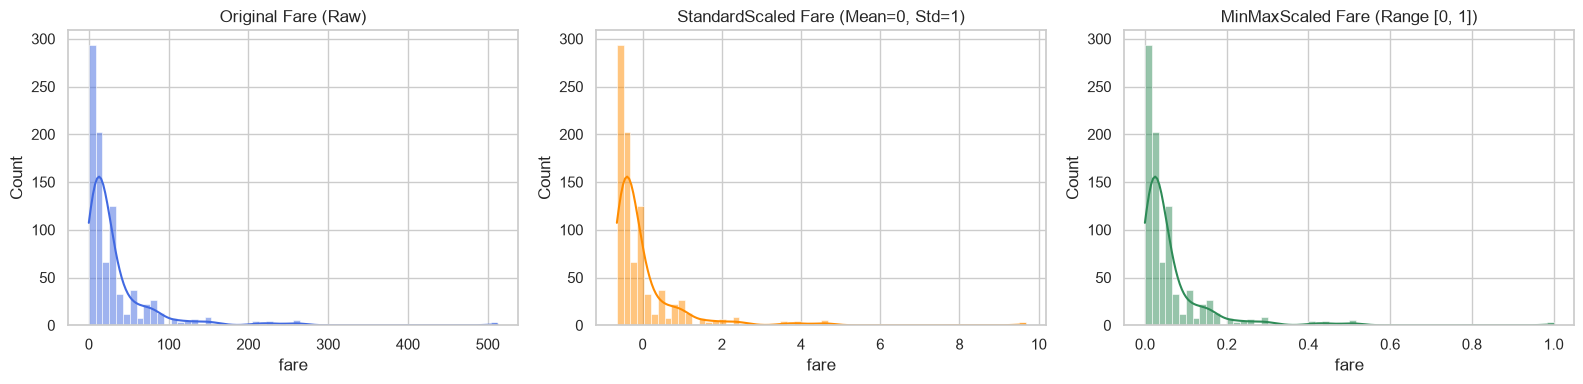

In [6]:
num_cols = ['age', 'fare']

# StandardScaler
std_scaler = StandardScaler()
df_std = df.copy()
df_std[num_cols] = std_scaler.fit_transform(df[num_cols])

# MinMaxScaler
minmax_scaler = MinMaxScaler()
df_minmax = df.copy()
df_minmax[num_cols] = minmax_scaler.fit_transform(df[num_cols])

# Visualize scaling effect on Fare
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['fare'], kde=True, ax=axes[0], color='royalblue')
axes[0].set_title("Original Fare (Raw)")

sns.histplot(df_std['fare'], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title("StandardScaled Fare (Mean=0, Std=1)")

sns.histplot(df_minmax['fare'], kde=True, ax=axes[2], color='seagreen')
axes[2].set_title("MinMaxScaled Fare (Range [0, 1])")

plt.tight_layout()
plt.show()

### Step 7: Outlier Detection and Capping via Interquartile Range (IQR)

In [7]:
# Calculate IQR bounds on raw 'fare'
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['fare'] < lower_bound) | (df['fare'] > upper_bound)]
print(f"IQR: {IQR:.2f} | Lower bound: {lower_bound:.2f} | Upper bound: {upper_bound:.2f}")
print(f"Identified {len(outliers)} outliers in 'fare' ({len(outliers)/len(df)*100:.2f}% of data)")

# Outlier capping (Winsorization) on raw feature
df_clean = df.copy()
df_clean['fare_capped'] = np.clip(df_clean['fare'], lower_bound, upper_bound)

# Apply StandardScaler to the capped feature
scaler_clean = StandardScaler()
df_clean[['age_scaled', 'fare_scaled']] = scaler_clean.fit_transform(df_clean[['age', 'fare_capped']])

print("\nTransformed dataset with capped and scaled features:")
print(df_clean[['age', 'age_scaled', 'fare', 'fare_capped', 'fare_scaled']].head())

IQR: 23.09 | Lower bound: 0.00 | Upper bound: 65.63
Identified 116 outliers in 'fare' (13.02% of data)

Transformed dataset with capped and scaled features:
    age  age_scaled     fare  fare_capped  fare_scaled
0  22.0   -0.565736   7.2500       7.2500    -0.820552
1  38.0    0.663861  71.2833      65.6344     2.031623
2  26.0   -0.258337   7.9250       7.9250    -0.787578
3  35.0    0.433312  53.1000      53.1000     1.419297
4  35.0    0.433312   8.0500       8.0500    -0.781471


### Step 8: Transformed Dataset Summary & Conclusion

In [8]:
print(f"Final Preprocessed Dataset Dimensions: {df_clean.shape}")
print("\nDescriptive Statistics of Transformed Dataset:")
df_clean.describe().round(3)

Final Preprocessed Dataset Dimensions: (891, 12)

Descriptive Statistics of Transformed Dataset:


,survived,pclass,sex,age,sibsp,parch,fare,embarked_Q,embarked_S,fare_capped,age_scaled,fare_scaled
count,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000
mean,0.384,2.309,0.352,29.362,0.523,0.382,32.204,0.086,0.725,24.047,0.000,0.000
std,0.487,0.836,0.478,13.020,1.103,0.806,49.693,0.281,0.447,20.482,1.001,1.001
min,0.000,1.000,0.000,0.420,0.000,0.000,0.000,0.000,0.000,0.000,-2.224,-1.175
25%,0.000,2.000,0.000,22.000,0.000,0.000,7.910,0.000,0.000,7.910,-0.566,-0.788
50%,0.000,3.000,0.000,28.000,0.000,0.000,14.454,0.000,1.000,14.454,-0.105,-0.469
75%,1.000,3.000,1.000,35.000,1.000,0.000,31.000,0.000,1.000,31.000,0.433,0.340
max,1.000,3.000,1.000,80.000,8.000,6.000,512.329,1.000,1.000,65.634,3.892,2.032


**Conclusion:**
In this experiment, foundational feature engineering steps were executed on the Titanic passenger dataset:
1. Missing values in continuous feature `age` were resolved via median imputation; missing categorical values in `embarked` were imputed with the mode.
2. Categorical features were encoded using binary mapping and One-Hot Encoding.
3. Feature distributions were standardized and normalized using `StandardScaler` and `MinMaxScaler`.
4. Severe positive skewness in `fare` was diagnosed via IQR outlier bounds and mitigated.